## 1. Import Library

In [4]:
import pandas as pd
import numpy as np
import re
import string
import nltk
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('wordnet', quiet=True)

True

## 2. Load Dataset

In [ ]:
file_path = "tmdb_5000_movies.csv"
df = pd.read_csv(file_path)
 
df = df[['title', 'overview']].rename(columns={'overview': 'text'})
print("Jumlah data awal:", df.shape)
print("Missing value per kolom:\n", df.isna().sum())
df.head()

Jumlah data awal: (4803, 2)
Missing value per kolom:
 title    0
text     3
dtype: int64


,title,text
0,Avatar,"In the 22nd century, a paraplegic Marine is di..."
1,Pirates of the Caribbean: At World's End,"Captain Barbossa, long believed to be dead, ha..."
2,Spectre,A cryptic message from Bond’s past sends him o...
3,The Dark Knight Rises,Following the death of District Attorney Harve...
4,John Carter,"John Carter is a war-weary, former military ca..."


In [6]:
df = df.dropna(subset=['text']).reset_index(drop=True)
print("Jumlah data setelah dropna:", df.shape)

Jumlah data setelah dropna: (4800, 2)


## 3. Preprocessing Teks

In [ ]:
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = text.lower()                                                   
    text = re.sub(r'\d+', '', text)                                       
    text = text.translate(str.maketrans('', '', string.punctuation))      
    words = word_tokenize(text)                                           
    words = [lemmatizer.lemmatize(word) for word in words]                
    return ' '.join(words)

df['clean_text'] = df['text'].apply(clean_text)
df[['text', 'clean_text']].head(3)

,text,clean_text
0,"In the 22nd century, a paraplegic Marine is di...",in the nd century a paraplegic marine is dispa...
1,"Captain Barbossa, long believed to be dead, ha...",captain barbossa long believed to be dead ha c...
2,A cryptic message from Bond’s past sends him o...,a cryptic message from bond ’ s past sends him...


## 4. Representasi Teks dengan TF-IDF

In [ ]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
custom_stopwords = list(ENGLISH_STOP_WORDS.union({'ha', 'wa', 'doe', 'u'}))

vectorizer = TfidfVectorizer(stop_words=custom_stopwords, max_df=0.5, min_df=5)-
X = vectorizer.fit_transform(df['clean_text'])
print("Bentuk matriks TF-IDF:", X.shape)

Bentuk matriks TF-IDF: (4800, 4420)


## 5. Menentukan Jumlah Klaster (Elbow & Silhouette)

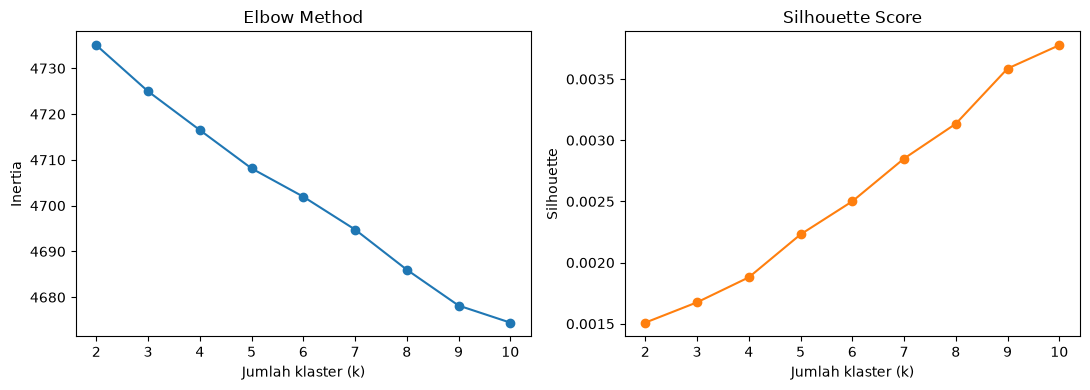

k=2: silhouette=0.0015
k=3: silhouette=0.0017
k=4: silhouette=0.0019
k=5: silhouette=0.0022
k=6: silhouette=0.0025
k=7: silhouette=0.0029
k=8: silhouette=0.0031
k=9: silhouette=0.0036
k=10: silhouette=0.0038


In [9]:
k_range = range(2, 11)
inertias, sil_scores = [], []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X, labels, random_state=42))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(list(k_range), inertias, marker='o')
ax[0].set_title("Elbow Method"); ax[0].set_xlabel("Jumlah klaster (k)"); ax[0].set_ylabel("Inertia")
ax[1].plot(list(k_range), sil_scores, marker='o', color='tab:orange')
ax[1].set_title("Silhouette Score"); ax[1].set_xlabel("Jumlah klaster (k)"); ax[1].set_ylabel("Silhouette")
plt.tight_layout(); plt.show()

for k, s in zip(k_range, sil_scores):
    print(f"k={k}: silhouette={s:.4f}")

## 6. Klasterisasi K-Means

In [10]:
num_clusters = 5
kmeans = KMeans(n_clusters=num_clusters, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X)

print("Jumlah film per klaster:")
print(df['cluster'].value_counts().sort_index())

Jumlah film per klaster:
cluster
0     213
1    2587
2     486
3     871
4     643
Name: count, dtype: int64


## 7. Visualisasi dengan PCA

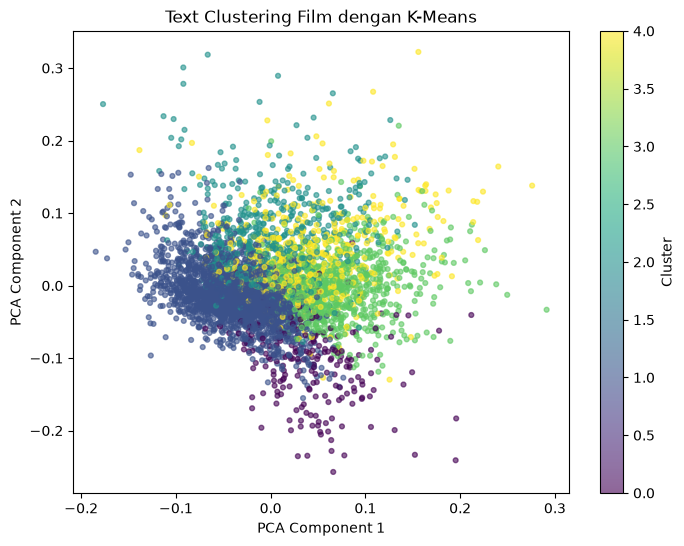

Varians yang dijelaskan 2 komponen: 0.0069


In [11]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X.toarray())

plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=df['cluster'], cmap='viridis', alpha=0.6, s=12)
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.title("Text Clustering Film dengan K-Means")
plt.colorbar(label='Cluster')
plt.show()

print("Varians yang dijelaskan 2 komponen:", pca.explained_variance_ratio_.sum().round(4))

## 8. Interpretasi Klaster

In [12]:
terms = vectorizer.get_feature_names_out()
order_centroids = kmeans.cluster_centers_.argsort()[:, ::-1]

for i in range(num_clusters):
    top_terms = [terms[idx] for idx in order_centroids[i, :10]]
    print(f"Klaster {i}: {', '.join(top_terms)}")

Klaster 0: school, high, student, teacher, friend, girl, college, senior, life, new
Klaster 1: world, new, friend, year, team, group, town, city, war, help
Klaster 2: story, film, true, based, tell, life, movie, world, war, set
Klaster 3: life, love, family, father, new, mother, son, woman, friend, year
Klaster 4: man, young, woman, world, life, friend, new, boy, help, father


In [13]:
for i in range(num_clusters):
    print(f"\nKlaster {i} ({(df['cluster']==i).sum()} film):")
    for t in df[df['cluster']==i]['title'].head(6):
        print("  -", t)


Klaster 0 (213 film):
  - Spider-Man
  - Harry Potter and the Philosopher's Stone
  - Grown Ups 2
  - A Beautiful Mind
  - Grown Ups
  - Anna and the King

Klaster 1 (2587 film):
  - Avatar
  - Spectre
  - The Dark Knight Rises
  - John Carter
  - Spider-Man 3
  - Tangled

Klaster 2 (486 film):
  - Titanic
  - Transformers: Dark of the Moon
  - The Lovers
  - The Curious Case of Benjamin Button
  - The Last Airbender
  - Puss in Boots

Klaster 3 (871 film):
  - Pirates of the Caribbean: At World's End
  - Harry Potter and the Half-Blood Prince
  - Pirates of the Caribbean: On Stranger Tides
  - Transformers: Revenge of the Fallen
  - The Amazing Spider-Man 2
  - Star Trek Into Darkness

Klaster 4 (643 film):
  - Superman Returns
  - Man of Steel
  - The Chronicles of Narnia: Prince Caspian
  - Robin Hood
  - Captain America: Civil War
  - Jack the Giant Slayer
